# House Prices – Análise Exploratória

> Alan Hoffmann Dos Santos

In [15]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [16]:
df = pd.read_csv('train.csv')
df_test = pd.read_csv('test.csv')
df.head()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [17]:
df.shape

(1460, 81)

In [18]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   str    
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   str    
 6   Alley          91 non-null     str    
 7   LotShape       1460 non-null   str    
 8   LandContour    1460 non-null   str    
 9   Utilities      1460 non-null   str    
 10  LotConfig      1460 non-null   str    
 11  LandSlope      1460 non-null   str    
 12  Neighborhood   1460 non-null   str    
 13  Condition1     1460 non-null   str    
 14  Condition2     1460 non-null   str    
 15  BldgType       1460 non-null   str    
 16  HouseStyle     1460 non-null   str    
 17  OverallQual    1460 non-null   int64  
 18  OverallCond    1460

## 1- Limpeza dos dados: verificar e resolver dados faltantes e/ou duplicados.

In [19]:
# Duplicados
df.duplicated().sum()

np.int64(0)

In [20]:
# Faltantes por coluna
df.isnull().sum().sort_values(ascending = False).head(20)

PoolQC          1453
MiscFeature     1406
Alley           1369
Fence           1179
MasVnrType       872
FireplaceQu      690
LotFrontage      259
GarageQual        81
GarageFinish      81
GarageType        81
GarageYrBlt       81
GarageCond        81
BsmtFinType2      38
BsmtExposure      38
BsmtCond          37
BsmtQual          37
BsmtFinType1      37
MasVnrArea         8
Electrical         1
Condition2         0
dtype: int64

In [21]:
# NA = "não possui" (sem piscina, sem cerca, sem garagem...) -> 'None'
nao_possui = ['PoolQC', 'MiscFeature', 'Alley', 'Fence', 'FireplaceQu',
              'GarageType', 'GarageFinish', 'GarageQual', 'GarageCond',
              'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1',
              'BsmtFinType2', 'MasVnrType']
df[nao_possui] = df[nao_possui].fillna('None')

In [22]:
# Áreas e quantidades vazias -> 0
zero = ['MasVnrArea', 'GarageCars', 'GarageArea', 'BsmtFinSF1', 'BsmtFinSF2',
        'BsmtUnfSF', 'TotalBsmtSF', 'BsmtFullBath', 'BsmtHalfBath']
df[zero] = df[zero].fillna(0)

In [23]:
# Ano da garagem vazio -> ano da casa
df['GarageYrBlt'] = df['GarageYrBlt'].fillna(df['YearBuilt'])

In [24]:
# Frente do terreno vazia -> mediana do bairro
df['LotFrontage'] = df['LotFrontage'].fillna(df.groupby('Neighborhood')['LotFrontage'].transform('median'))

In [25]:
# Elétrica vazia (1 casa) -> valor mais comum
df['Electrical'] = df['Electrical'].fillna(df['Electrical'].mode()[0])

In [26]:
# Conferindo
df.isnull().sum().sum()

np.int64(0)

In [27]:
# Mesmo tratamento na base de teste
df_test[nao_possui] = df_test[nao_possui].fillna('None')
df_test[zero] = df_test[zero].fillna(0)
df_test['GarageYrBlt'] = df_test['GarageYrBlt'].fillna(df_test['YearBuilt'])
df_test['LotFrontage'] = df_test['LotFrontage'].fillna(df_test.groupby('Neighborhood')['LotFrontage'].transform('median'))
for coluna in df_test.columns[df_test.isnull().any()]:
    df_test[coluna] = df_test[coluna].fillna(df[coluna].mode()[0])
df_test.isnull().sum().sum()

np.int64(0)

## 2- Exporte seus dados limpos em um arquivo .csv.

In [28]:
df.to_csv('train_limpo.csv', index = False)
df_test.to_csv('test_limpo.csv', index = False)

## 3- Elencar dados que são categóricos e dados que são numéricos.

In [29]:
numericas = df.select_dtypes(include = 'number').columns.tolist()
categoricas = df.select_dtypes(exclude = 'number').columns.tolist()
len(numericas), len(categoricas)

(38, 43)

In [30]:
# Id não é variável, MSSubClass é um código (categoria), SalePrice é o alvo
numericas.remove('Id')
numericas.remove('MSSubClass')
numericas.remove('SalePrice')
categoricas.append('MSSubClass')
len(numericas), len(categoricas)

(35, 44)

In [31]:
numericas

['LotFrontage',
 'LotArea',
 'OverallQual',
 'OverallCond',
 'YearBuilt',
 'YearRemodAdd',
 'MasVnrArea',
 'BsmtFinSF1',
 'BsmtFinSF2',
 'BsmtUnfSF',
 'TotalBsmtSF',
 '1stFlrSF',
 '2ndFlrSF',
 'LowQualFinSF',
 'GrLivArea',
 'BsmtFullBath',
 'BsmtHalfBath',
 'FullBath',
 'HalfBath',
 'BedroomAbvGr',
 'KitchenAbvGr',
 'TotRmsAbvGrd',
 'Fireplaces',
 'GarageYrBlt',
 'GarageCars',
 'GarageArea',
 'WoodDeckSF',
 'OpenPorchSF',
 'EnclosedPorch',
 '3SsnPorch',
 'ScreenPorch',
 'PoolArea',
 'MiscVal',
 'MoSold',
 'YrSold']

In [32]:
categoricas

['MSZoning',
 'Street',
 'Alley',
 'LotShape',
 'LandContour',
 'Utilities',
 'LotConfig',
 'LandSlope',
 'Neighborhood',
 'Condition1',
 'Condition2',
 'BldgType',
 'HouseStyle',
 'RoofStyle',
 'RoofMatl',
 'Exterior1st',
 'Exterior2nd',
 'MasVnrType',
 'ExterQual',
 'ExterCond',
 'Foundation',
 'BsmtQual',
 'BsmtCond',
 'BsmtExposure',
 'BsmtFinType1',
 'BsmtFinType2',
 'Heating',
 'HeatingQC',
 'CentralAir',
 'Electrical',
 'KitchenQual',
 'Functional',
 'FireplaceQu',
 'GarageType',
 'GarageFinish',
 'GarageQual',
 'GarageCond',
 'PavedDrive',
 'PoolQC',
 'Fence',
 'MiscFeature',
 'SaleType',
 'SaleCondition',
 'MSSubClass']

## 4- Utilizar métodos de estatística como medidas de tendência central entre outros para verificar intervalos e a distribuição dos dados.

In [33]:
df[numericas].describe().T

,count,mean,std,min,25%,50%,75%,max
LotFrontage,1460.0,70.199658,22.431902,21.0,60.00,70.0,80.00,313.0
LotArea,1460.0,10516.828082,9981.264932,1300.0,7553.50,9478.5,11601.50,215245.0
OverallQual,1460.0,6.099315,1.382997,1.0,5.00,6.0,7.00,10.0
OverallCond,1460.0,5.575342,1.112799,1.0,5.00,5.0,6.00,9.0
YearBuilt,1460.0,1971.267808,30.202904,1872.0,1954.00,1973.0,2000.00,2010.0
YearRemodAdd,1460.0,1984.865753,20.645407,1950.0,1967.00,1994.0,2004.00,2010.0
MasVnrArea,1460.0,103.117123,180.731373,0.0,0.00,0.0,164.25,1600.0
BsmtFinSF1,1460.0,443.639726,456.098091,0.0,0.00,383.5,712.25,5644.0
BsmtFinSF2,1460.0,46.549315,161.319273,0.0,0.00,0.0,0.00,1474.0
BsmtUnfSF,1460.0,567.240411,441.866955,0.0,223.00,477.5,808.00,2336.0


In [34]:
df['SalePrice'].mean()

np.float64(180921.19589041095)

In [35]:
df['SalePrice'].median()

np.float64(163000.0)

In [36]:
df['SalePrice'].mode()

0    140000
Name: SalePrice, dtype: int64

In [37]:
df['SalePrice'].std()

np.float64(79442.50288288662)

In [38]:
df['SalePrice'].quantile([0.25, 0.5, 0.75])

0.25    129975.0
0.50    163000.0
0.75    214000.0
Name: SalePrice, dtype: float64

In [39]:
df['SalePrice'].skew()

np.float64(1.8828757597682118)

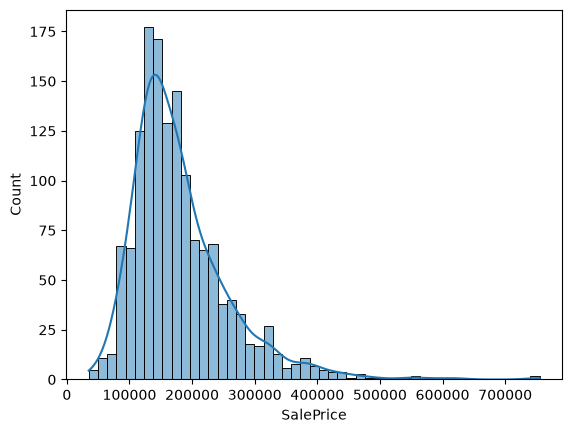

In [40]:
sns.histplot(df['SalePrice'], kde = True)
plt.show()

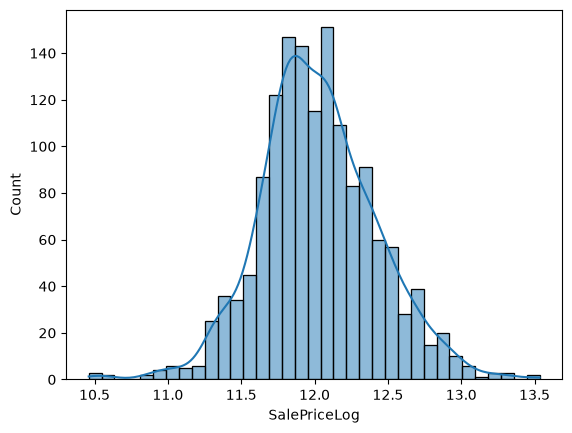

In [41]:
# Logaritmo do preço (a competição avalia o erro em log)
df['SalePriceLog'] = np.log1p(df['SalePrice'])
sns.histplot(df['SalePriceLog'], kde = True)
plt.show()

In [42]:
df.groupby(['Neighborhood'])['SalePrice'].mean().sort_values(ascending = False)

Neighborhood
NoRidge    335295.317073
NridgHt    316270.623377
StoneBr    310499.000000
Timber     242247.447368
Veenker    238772.727273
Somerst    225379.837209
ClearCr    212565.428571
Crawfor    210624.725490
CollgCr    197965.773333
Blmngtn    194870.882353
Gilbert    192854.506329
NWAmes     189050.068493
SawyerW    186555.796610
Mitchel    156270.122449
NAmes      145847.080000
NPkVill    142694.444444
SWISU      142591.360000
Blueste    137500.000000
Sawyer     136793.135135
OldTown    128225.300885
Edwards    128219.700000
BrkSide    124834.051724
BrDale     104493.750000
IDOTRR     100123.783784
MeadowV     98576.470588
Name: SalePrice, dtype: float64

In [43]:
df.groupby(['OverallQual'])['SalePrice'].mean()

OverallQual
1      50150.000000
2      51770.333333
3      87473.750000
4     108420.655172
5     133523.347607
6     161603.034759
7     207716.423197
8     274735.535714
9     367513.023256
10    438588.388889
Name: SalePrice, dtype: float64

## 5- Plotar gráficos de dispersão capaz de mostrar relação entre as grandezas e possíveis correlações.

In [44]:
corr = df.corr(numeric_only = True)
corr['SalePrice'].sort_values(ascending = False)

SalePrice        1.000000
SalePriceLog     0.948374
OverallQual      0.790982
GrLivArea        0.708624
GarageCars       0.640409
GarageArea       0.623431
TotalBsmtSF      0.613581
1stFlrSF         0.605852
FullBath         0.560664
TotRmsAbvGrd     0.533723
YearBuilt        0.522897
GarageYrBlt      0.508043
YearRemodAdd     0.507101
MasVnrArea       0.472614
Fireplaces       0.466929
BsmtFinSF1       0.386420
LotFrontage      0.349876
WoodDeckSF       0.324413
2ndFlrSF         0.319334
OpenPorchSF      0.315856
HalfBath         0.284108
LotArea          0.263843
BsmtFullBath     0.227122
BsmtUnfSF        0.214479
BedroomAbvGr     0.168213
ScreenPorch      0.111447
PoolArea         0.092404
MoSold           0.046432
3SsnPorch        0.044584
BsmtFinSF2      -0.011378
BsmtHalfBath    -0.016844
MiscVal         -0.021190
Id              -0.021917
LowQualFinSF    -0.025606
YrSold          -0.028923
OverallCond     -0.077856
MSSubClass      -0.084284
EnclosedPorch   -0.128578
KitchenAbvGr

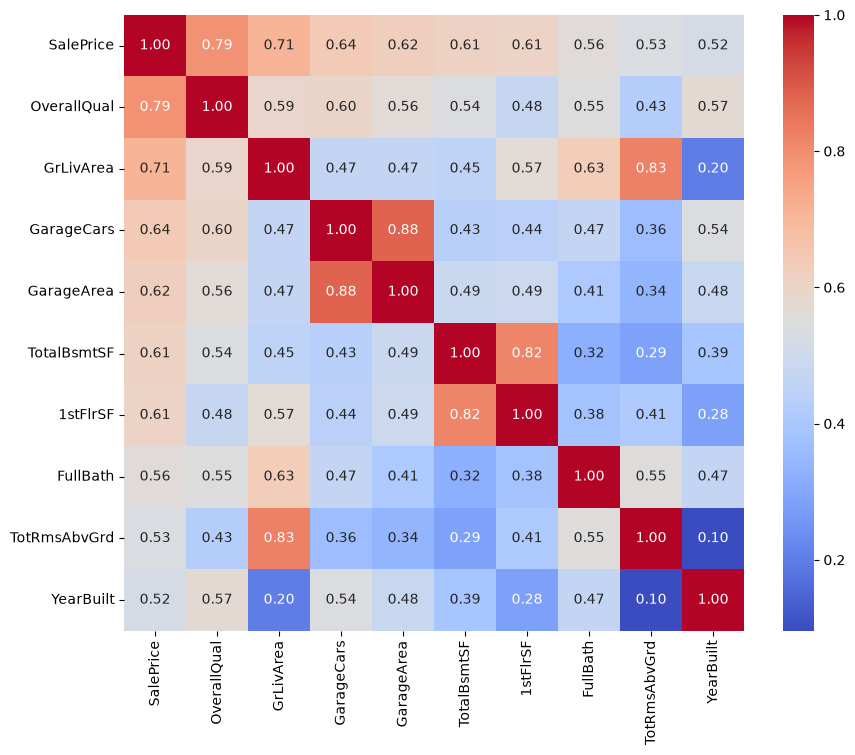

In [45]:
top = ['SalePrice', 'OverallQual', 'GrLivArea', 'GarageCars', 'GarageArea',
       'TotalBsmtSF', '1stFlrSF', 'FullBath', 'TotRmsAbvGrd', 'YearBuilt']
plt.figure(figsize = (10, 8))
sns.heatmap(df[top].corr(), annot = True, fmt = '.2f', cmap = 'coolwarm')
plt.show()

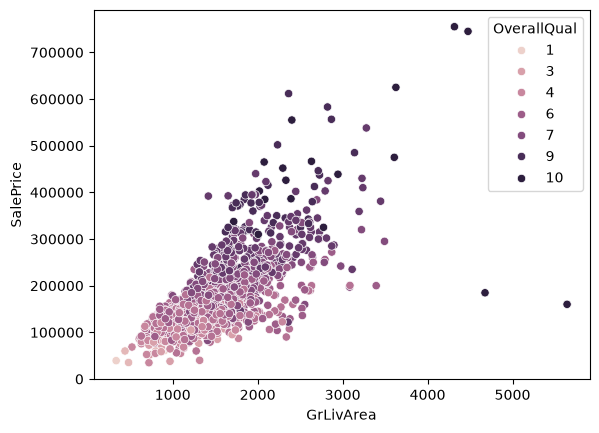

In [46]:
sns.scatterplot(x = 'GrLivArea', y = 'SalePrice', hue = 'OverallQual', data = df)
plt.show()

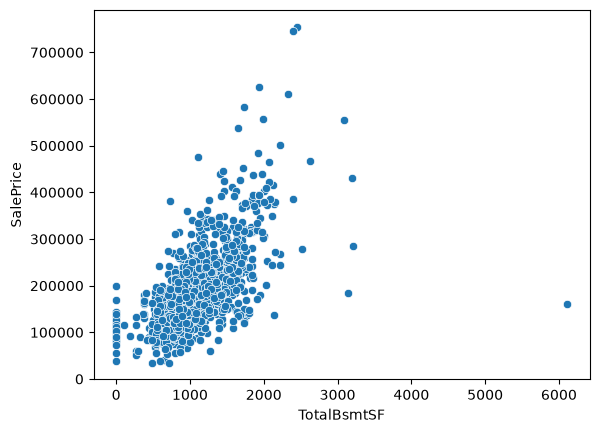

In [47]:
sns.scatterplot(x = 'TotalBsmtSF', y = 'SalePrice', data = df)
plt.show()

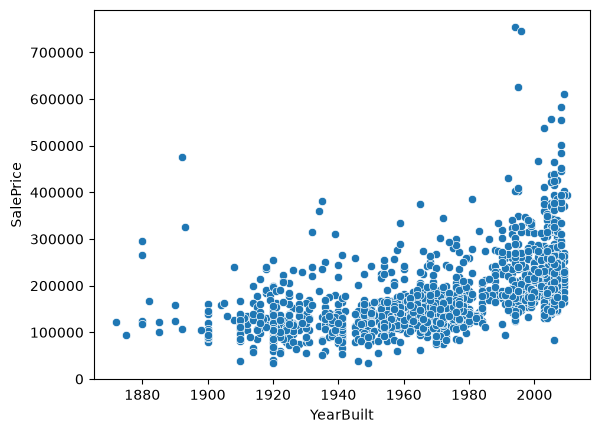

In [48]:
sns.scatterplot(x = 'YearBuilt', y = 'SalePrice', data = df)
plt.show()

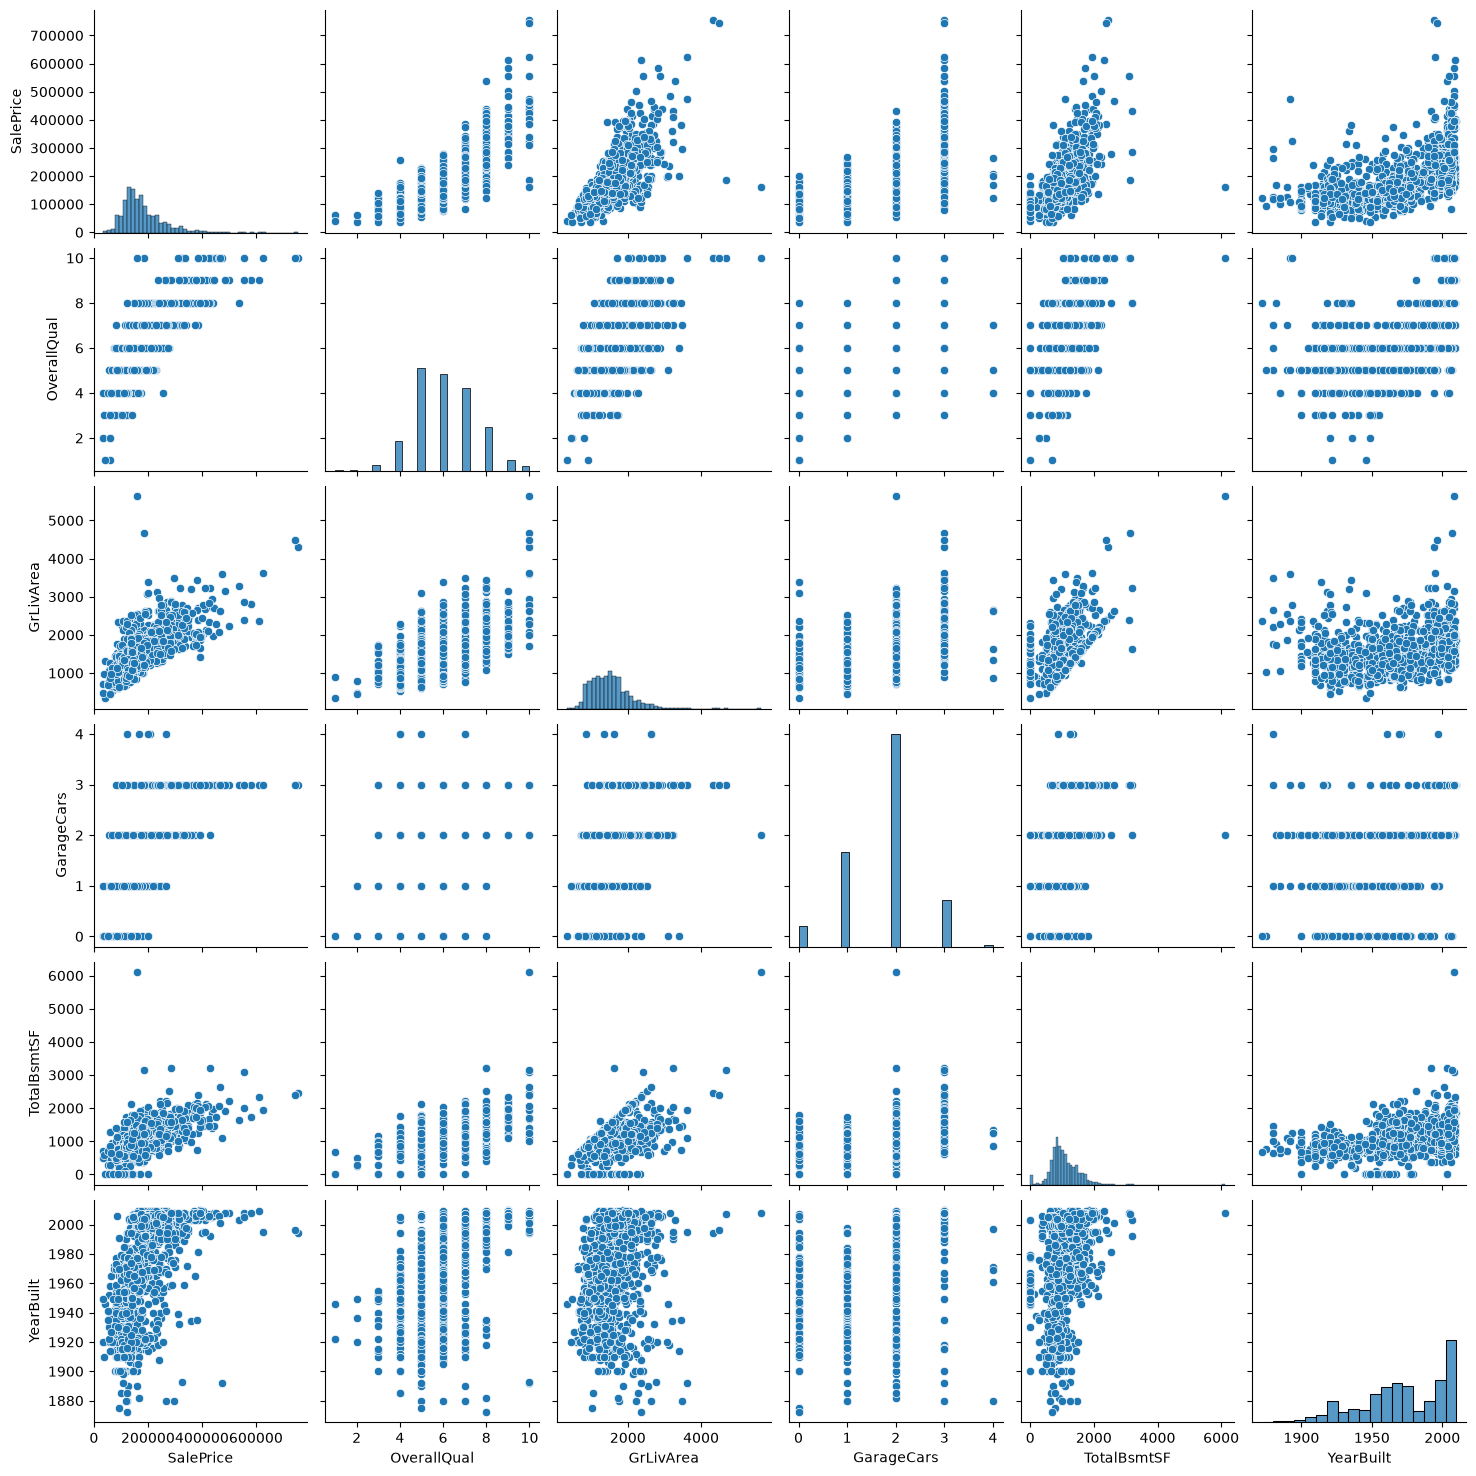

In [49]:
sns.pairplot(df[['SalePrice', 'OverallQual', 'GrLivArea', 'GarageCars', 'TotalBsmtSF', 'YearBuilt']])
plt.show()

In [51]:
pip install ppscore

Note: you may need to restart the kernel to use updated packages.


In [52]:
import ppscore as pps

In [53]:
pps.predictors(df[top + ['Neighborhood', 'KitchenQual']], 'SalePrice')[['x', 'ppscore']]

,x,ppscore
0,OverallQual,0.440962
1,Neighborhood,0.340940
2,GarageCars,0.296431
3,KitchenQual,0.261966
4,YearBuilt,0.198485
5,FullBath,0.195689
6,GarageArea,0.187993
7,TotRmsAbvGrd,0.147185
8,GrLivArea,0.100166
9,TotalBsmtSF,0.052363


## 6- Verificar a presença de outliers e analisar se os mesmos devem ou não permanecer nos dados. Use boxplot para esta análise.

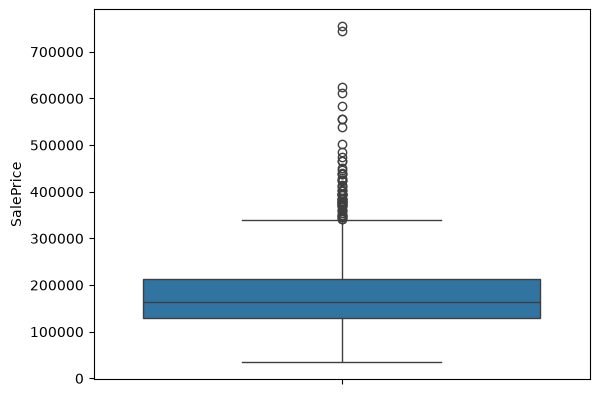

In [54]:
sns.boxplot(y = 'SalePrice', data = df)
plt.show()

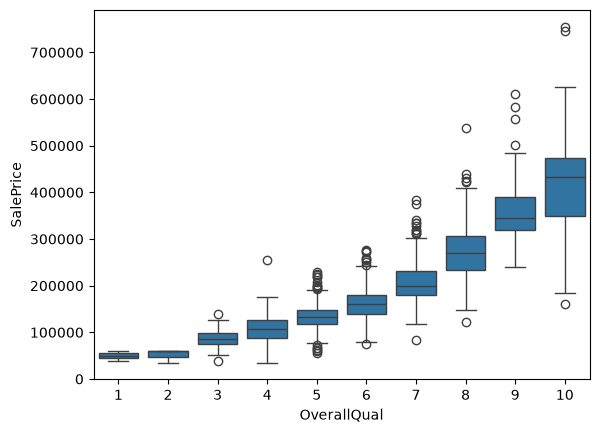

In [55]:
sns.boxplot(x = 'OverallQual', y = 'SalePrice', data = df)
plt.show()

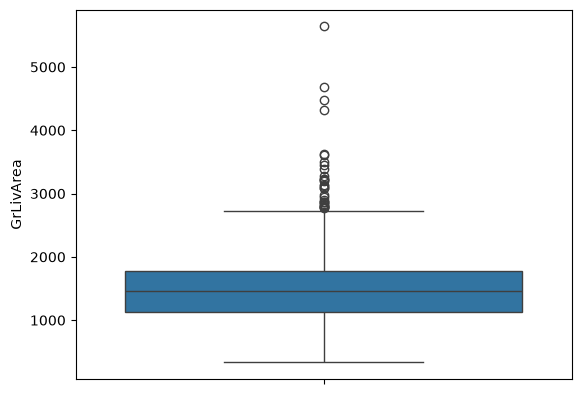

In [56]:
sns.boxplot(y = 'GrLivArea', data = df)
plt.show()

In [57]:
# Limite superior pelo IQR
Q1 = df['SalePrice'].quantile(0.25)
Q3 = df['SalePrice'].quantile(0.75)
limite = Q3 + 1.5 * (Q3 - Q1)
df.loc[df['SalePrice'] > limite].shape[0]

61

In [58]:
# As casas acima do limite são de alta qualidade -> ficam
df.loc[df['SalePrice'] > limite]['OverallQual'].mean()

np.float64(8.754098360655737)

In [59]:
# Casas enormes vendidas barato -> fogem do padrão
df.loc[(df['GrLivArea'] > 4000) & (df['SalePrice'] < 300000)]

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice,SalePriceLog
523,524,60,RL,130.0,40094,Pave,None,IR1,Bnk,AllPub,...,None,None,None,0,10,2007,New,Partial,184750,12.126764
1298,1299,60,RL,313.0,63887,Pave,None,IR3,Bnk,AllPub,...,Gd,None,None,0,1,2008,New,Partial,160000,11.982935


In [60]:
# Removendo só essas 2
df = df.drop(df.loc[(df['GrLivArea'] > 4000) & (df['SalePrice'] < 300000)].index)
df.shape

(1458, 82)

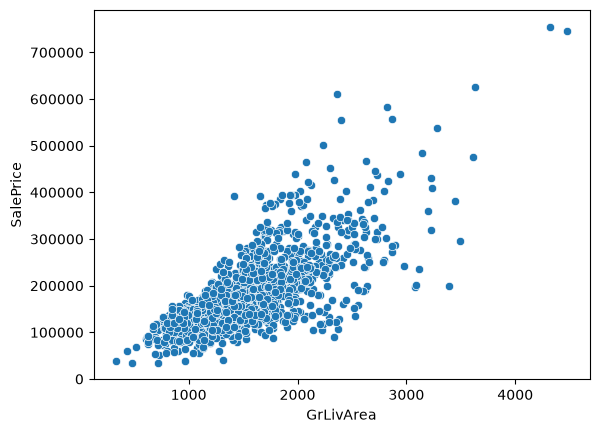

In [61]:
sns.scatterplot(x = 'GrLivArea', y = 'SalePrice', data = df)
plt.show()

## 7- Crie 5 perguntas aos seus dados e responda por meio da criação de filtros. Estas perguntas geram insights sobre os dados? quais?

In [62]:
# 1) Casas com ar central são mais caras?
df.loc[df['CentralAir'] == 'Y']['SalePrice'].mean(), df.loc[df['CentralAir'] == 'N']['SalePrice'].mean()

(np.float64(186206.9765223771), np.float64(105264.07368421053))

In [63]:
# 2) Casas de 2000 em diante x casas antes de 1950
df.loc[df['YearBuilt'] >= 2000]['SalePrice'].mean(), df.loc[df['YearBuilt'] < 1950]['SalePrice'].mean()

(np.float64(242802.18911917097), np.float64(132269.0786163522))

In [64]:
# 3) Garagem para 3+ carros x garagem para 1 carro
df.loc[df['GarageCars'] >= 3]['SalePrice'].mean(), df.loc[df['GarageCars'] == 1]['SalePrice'].mean()

(np.float64(307149.5513513514), np.float64(128116.68834688347))

In [65]:
# 4) Vendas anormais (hipoteca, venda forçada) são mais baratas?
df.groupby(['SaleCondition'])['SalePrice'].mean().sort_values()

SaleCondition
AdjLand    104125.000000
Abnorml    146526.623762
Family     149600.000000
Alloca     167377.416667
Normal     175202.219533
Partial    273916.414634
Name: SalePrice, dtype: float64

In [66]:
# 5) Casa mais cara em NridgHt com qualidade >= 8 e até 3 quartos
df_nridght = df.loc[df['Neighborhood'] == 'NridgHt']
df_nridght = df_nridght.loc[(df_nridght['OverallQual'] >= 8) & (df_nridght['BedroomAbvGr'] <= 3)]
df_nridght.loc[df_nridght['SalePrice'] == df_nridght['SalePrice'].max()]

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice,SalePriceLog
898,899,20,RL,100.0,12919,Pave,None,IR1,Lvl,AllPub,...,None,None,None,0,3,2010,New,Partial,611657,13.323929


**Insights:** ar central (US$ 186 mil x 105 mil), casas novas (243 mil x 132 mil) e garagem grande (307 mil x 128 mil) valem bem mais. Vendas anormais saem ~16% mais baratas que as normais. Em NridgHt, a casa mais cara tem só 2 quartos: qualidade e localização pesam mais que o número de quartos.

## 8- Define o que seria interessante ter como objetivo do primeiro algoritmo de aprendizado de máquina, uma regressão? uma classificação? de que variável? quais variáveis seriam a entrada do modelo?

- **Regressão**, pois o `SalePrice` é um número contínuo.
- **Saída:** `log(SalePrice)`.
- **Entradas:** as variáveis mais correlacionadas com o preço + qualidades convertidas em número.

In [67]:
# Convertendo qualidade em número: Ex=5, Gd=4, TA=3, Fa=2, Po=1, None=0
qualidade = {'Ex': 5, 'Gd': 4, 'TA': 3, 'Fa': 2, 'Po': 1, 'None': 0}
df['ExterQual'] = df['ExterQual'].map(qualidade)
df['KitchenQual'] = df['KitchenQual'].map(qualidade)
df['BsmtQual'] = df['BsmtQual'].map(qualidade)
df['CentralAir'] = df['CentralAir'].map({'Y': 1, 'N': 0})

In [68]:
variaveis = ['OverallQual', 'GrLivArea', 'GarageCars', 'TotalBsmtSF', 'FullBath',
             'TotRmsAbvGrd', 'YearBuilt', 'YearRemodAdd', 'Fireplaces', 'MasVnrArea',
             'LotArea', 'ExterQual', 'KitchenQual', 'BsmtQual', 'CentralAir']
df[variaveis + ['SalePrice']].corr()['SalePrice'].sort_values(ascending = False)

SalePrice       1.000000
OverallQual     0.795774
GrLivArea       0.734968
ExterQual       0.686756
KitchenQual     0.662236
TotalBsmtSF     0.651153
GarageCars      0.641047
BsmtQual        0.586674
FullBath        0.562165
TotRmsAbvGrd    0.537769
YearBuilt       0.523608
YearRemodAdd    0.507717
MasVnrArea      0.477810
Fireplaces      0.469862
LotArea         0.268179
CentralAir      0.251385
Name: SalePrice, dtype: float64

## 9- Exporte apenas as variáveis de interesse para um arquivo .csv.

In [69]:
df[variaveis + ['SalePrice']].to_csv('variaveis_interesse.csv', index = False)

## 10- Defina o que é normalização e padronização de dados (cite a referência utilizada).

- **Normalização (Min-Max):** coloca os valores entre 0 e 1 → `(x - mínimo) / (máximo - mínimo)`
- **Padronização (Z-score):** deixa média 0 e desvio padrão 1 → `(x - média) / desvio padrão`

Referências: GÉRON, A. *Mãos à Obra: Aprendizado de Máquina com Scikit-Learn, Keras & TensorFlow*. 2. ed. Alta Books, 2021 (cap. 2). SCIKIT-LEARN. *Preprocessing data*. https://scikit-learn.org/stable/modules/preprocessing.html

## 11- Efetue estas operações nas variáveis de interesse.

In [70]:
# Normalização
df_normalizado = df[variaveis + ['SalePrice']].copy()
df_normalizado[variaveis] = (df[variaveis] - df[variaveis].min()) / (df[variaveis].max() - df[variaveis].min())
df_normalizado.describe().loc[['min', 'max']]

,OverallQual,GrLivArea,GarageCars,TotalBsmtSF,FullBath,TotRmsAbvGrd,YearBuilt,YearRemodAdd,Fireplaces,MasVnrArea,LotArea,ExterQual,KitchenQual,BsmtQual,CentralAir,SalePrice
min,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,34900.0
max,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,755000.0


In [71]:
# Padronização
df_padronizado = df[variaveis + ['SalePrice']].copy()
df_padronizado[variaveis] = (df[variaveis] - df[variaveis].mean()) / df[variaveis].std()
df_padronizado.describe().loc[['mean', 'std']].round(2)

,OverallQual,GrLivArea,GarageCars,TotalBsmtSF,FullBath,TotRmsAbvGrd,YearBuilt,YearRemodAdd,Fireplaces,MasVnrArea,LotArea,ExterQual,KitchenQual,BsmtQual,CentralAir,SalePrice
mean,-0.0,-0.0,-0.0,0.0,0.0,0.0,0.0,0.0,-0.0,0.0,0.0,-0.0,-0.0,-0.0,0.0,180932.92
std,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,79495.06


## 12- Salve um arquivo .csv com as variáveis normalizadas e um outro com as variáveis padronizadas.

In [72]:
df_normalizado.to_csv('dados_normalizados.csv', index = False)
df_padronizado.to_csv('dados_padronizados.csv', index = False)